#TUGAS LAB 2


## Pilih salah satu dataset nyata dari sklearn.datasets (misalnya iris dataset atau digits dataset).

## Lakukan clustering dengan HDBSCAN.

## Laporkan hasil:

*   Jumlah cluster yang terbentuk.
*   Banyaknya noise.
*   Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu, dikarenakan visualisasi hanya dapat dilakukan hingga 3 dimensi).

## Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut

=== Laporan Hasil HDBSCAN pada Dataset Iris ===
Jumlah klaster yang terbentuk: 2
Banyaknya noise: 0 data


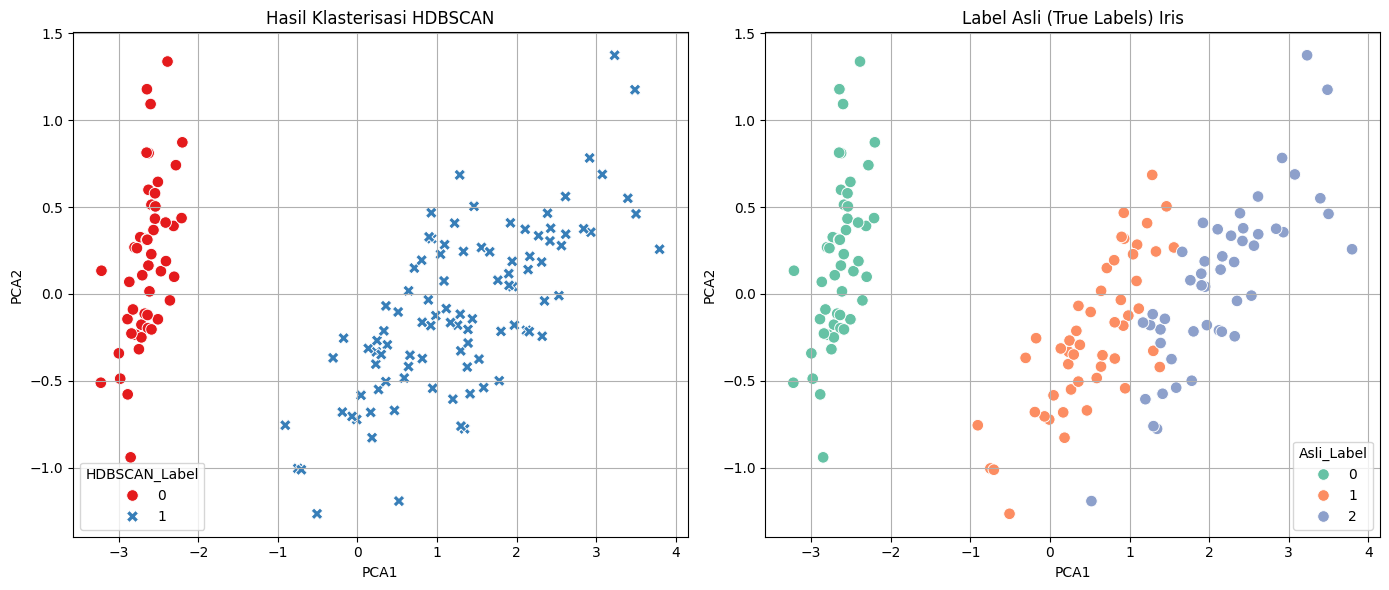

Adjusted Rand Index (Kesamaan label asli vs HDBSCAN): 0.5681


In [26]:
from sklearn.datasets import load_iris
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# 1. Load Dataset Iris
iris = load_iris()
X_iris = iris.data
y_iris_true = iris.target # Label asli

# 2. Membangun model HDBSCAN
# min_cluster_size menentukan ukuran terkecil yang bisa dianggap sebuah cluster
hdb = HDBSCAN(min_cluster_size=10, min_samples=5)
hdb_labels = hdb.fit_predict(X_iris)
# Hitung jumlah cluster dan jumlah noise (noise di HDBSCAN dilabeli -1)
jumlah_klaster = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)
jumlah_noise = list(hdb_labels).count(-1)

print("=== Laporan Hasil HDBSCAN pada Dataset Iris ===")
print(f"Jumlah klaster yang terbentuk: {jumlah_klaster}")
print(f"Banyaknya noise: {jumlah_noise} data")

# 3. Reduksi Dimensi dengan PCA untuk Visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_iris)

# Gabungkan data untuk visualisasi
df_iris = pd.DataFrame(data=X_pca, columns=['PCA1', 'PCA2'])
df_iris['HDBSCAN_Label'] = hdb_labels
df_iris['Asli_Label'] = y_iris_true

# 4. Visualisasi (Perbandingan HDBSCAN vs Asli)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Plot hasil HDBSCAN
sns.scatterplot(ax=axes[0], data=df_iris, x='PCA1', y='PCA2',
                hue='HDBSCAN_Label', palette='Set1', s=70, style='HDBSCAN_Label')
axes[0].set_title('Hasil Klasterisasi HDBSCAN')
axes[0].grid(True)
# Plot Label Asli
sns.scatterplot(ax=axes[1], data=df_iris, x='PCA1', y='PCA2',
                hue='Asli_Label', palette='Set2', s=70)
axes[1].set_title('Label Asli (True Labels) Iris')
axes[1].grid(True)
plt.tight_layout()
plt.show()

# Evaluasi kesamaan klaster HDBSCAN dengan Label Asli menggunakan Adjusted Rand Index (opsional tapi bagus untuk analisis)
ari_score = adjusted_rand_score(y_iris_true, hdb_labels)
print(f"Adjusted Rand Index (Kesamaan label asli vs HDBSCAN): {ari_score:.4f}")